In [3]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

X, y = make_classification(n_samples=1000, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

rf = RandomForestClassifier(n_estimators=100)
search = GridSearchCV(GradientBoostingClassifier(n_estimators=300, n_iter_no_change=5, random_state=42), {"learning_rate": [0.03, 0.1, 0.2]}, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
gb = search.best_estimator_

models = {
    "Bagging": BaggingClassifier(n_estimators=100, random_state=42),
    "RandomForest": rf,
    "Boosting": gb,
    "Stacking": StackingClassifier(
        [("rf", rf), ("gb", gb)],
        final_estimator=LogisticRegression(), cv=5
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, "accuracy:", round(accuracy_score(y_test, pred), 3), "macro-F1:", round(f1_score(y_test, pred, average="macro"), 3))

Bagging accuracy: 0.92 macro-F1: 0.92
RandomForest accuracy: 0.885 macro-F1: 0.885
Boosting accuracy: 0.895 macro-F1: 0.895
Stacking accuracy: 0.9 macro-F1: 0.9


In [6]:
import numpy as np 

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

sigmoid = lambda z: 1 / (1 + np.exp(-z))

W1 = np.random.randn(2, 4)
W2 = np.random.randn(4, 1)
b1 = np.zeros((1, 4))
b2 = np.zeros((1, 4))

for _ in range(1000):
    # FP
    h = sigmoid(X @ W1 + b1)
    pred = sigmoid(h @ W2 + b2)

    # BP
    d2 = (pred - y) / len(X)
    dW2, db2 = h.T @ d2, d2.sum(axis=0, keepdims=True)
    d1 = (d2 * W2.T) * h * (1-h)
    dW1, db1 = X.T @ d1, d1.sum(axis=0, keepdims=True)

    # Gradient Descent 
    W1 -= dW1 
    b1 -= db1 
    W2 -= dW2 
    b2 -= db2 

print((pred > 0.5).astype(int).ravel())

ValueError: non-broadcastable output operand with shape (4,1) doesn't match the broadcast shape (4,4)

In [8]:
import pandas as pd 
import matplotlib.pyplot as plt 
import statsmodels.api as sm 
from statsmodels.tsa.seasonal import seasonal_decompose

series = sm.datasets.get_rdataset("AirPassengers").data["value"]

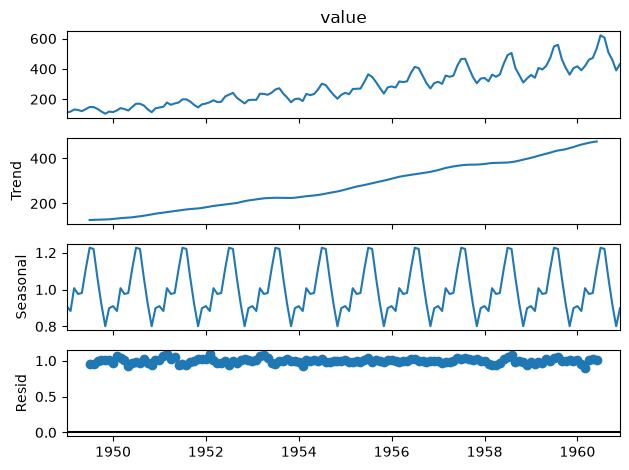

In [9]:
series.index = pd.date_range("1949-01-01", periods=len(series), freq="MS")

result = seasonal_decompose(series,model="multiplicative")
result.plot()
plt.tight_layout()
plt.show()

In [10]:
from statsmodels.tsa.stattools import adfuller 

diff = series.diff(12).diff()
p = adfuller(diff.dropna())[1]

print(f"p-value={p}")

p-value=1.8565116001234439e-28


/var/folders/xj/k0m7g06133vf7zhcrt6zz78h0000gn/T/ipykernel_86099/2656336617.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p = adfuller(diff.dropna())[1]


0.03747482770123841


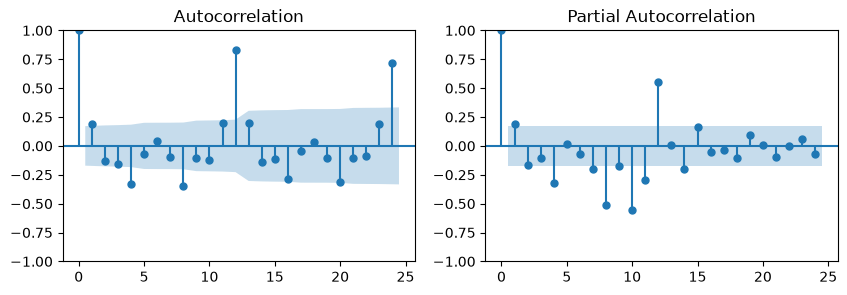

In [11]:
import numpy as np 
import matplotlib.pyplot as plt 
import statsmodels.api as sm 
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

series = sm.datasets.get_rdataset("AirPassengers").data["value"]

y = np.log(series)

train, test = y.iloc[:-12], y.iloc[-12:]

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
plot_acf(train.diff().dropna(), lags=24, ax=ax[0])
plot_pacf(train.diff().dropna(), lags=24,method="ywm", ax=ax[1])

model = ARIMA(train, order=(1, 1, 1))
fitted_model = model.fit()

forecast = fitted_model.forecast(steps=len(test))
mse = mean_squared_error(test, forecast)

print(mse)

In [12]:
import numpy as np 
import matplotlib.pyplot as plt 
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing

models = {
    'SARIMAX': SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False),
    'Single': SimpleExpSmoothing(train, initialization_method="estimated").fit(),
    'Double': Holt(train, initialization_method="estimated").fit(),
    'Holt-winter': ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated").fit(),
}

forecasts = {name: model.forecast(12) for name, model in models.items()}

for name, forecast in forecasts.items():
    rmse = np.sqrt(mean_squared_error(np.exp(test), np.exp(forecast)))
    print(f"{name} Rmse: {rmse}")

SARIMAX Rmse: 18.81002690060118
Single Rmse: 102.97653501201488
Double Rmse: 85.56409317268802
Holt-winter Rmse: 28.688433945924405


In [13]:
# RNN
import numpy as np 

wx, wh, wy = 0.1, 0.1, 0.1 
lr = 0.01

X = [1.0, 2.0, 3.0]
Y = [2.0, 3.0, 4.0]


# FP
H = [0.0]
Y_pred = []

for x in X:
    h = np.tanh(wx * x + wh * H[-1])
    H.append(h)
    Y_pred.append(wy * h)

# BP
dwx = dwh = dwy = 0
dh_next = 0

for t in reversed(range(len(X))):
    dy = Y_pred[t] - Y[t]
    dwy += dy * H[t-1]

    dh = wy * dy + dh_next
    dh_raw = (1 - H[t+1] ** 2) * dh

    dwx += dh_raw * X[t]
    dwh += dh_raw * H[t]
    dh_next = wh * dh_raw 

wx -= lr * dwx 
wh -= lr * dwh 
wy -= lr * dwy 

print(Y_pred)




[np.float64(0.009966799462495582), np.float64(0.020693472112300316), np.float64(0.031013382783067464)]


In [15]:
import tensorflow as tf

X = tf.constant([[[1.0], [2.0], [3.0]]])
Y = tf.constant([[[2.0], [3.0], [4.0]]])

for layer in [tf.keras.layers.LSTM, tf.keras.layers.GRU]:
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(3, 1)),
        layer(1, return_sequences=True),
        tf.keras.layers.Dense(1)
    ])

    model.compile(optimizer="adam", loss="mse")
    model.fit(X, Y, epochs=200, verbose=0)

    print(layer.__name__, model.predict(X, verbose=0).ravel())

LSTM [0.43352556 0.7689199  1.0990478 ]
GRU [0.7042232 0.9866385 1.0904665]


In [ ]:
# Convulational Neural Networks
import tensorflow as tf 
from tensorflow.keras import layers 

(x_train, y_train), (x_test, y_train) = tf.keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1, 28, 28, 1) / 255.0
y_train = y_train.reshape(-1, 28, 28, 1) / 255.0

model = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(8, 3, activation="relu"),
    layers.MaxPool2D(2),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.fit(x_train, y_train, epochs=3)

In [ ]:
import cv2 
import numpy as np
import matplotlib.pyplot as plt 

img = cv2.imread("img.jpg")

h, w = img.shape[:2]

resized = cv2.resize(img, (256, 256))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
normalized = resized.astype(np.float32) / 255.0

flipped = cv2.flip(img, 1)
M = cv2.getRotationMatrix2D((w/2, h/2), 15, 1.0)
rotated = cv2.warpAffine(img, M, (w, h))

adjusted = cv2.convertScaleAbs(img, alpha=1.2, beta=20)

overlay = img.copy()
cv2.putText(overlay, "Sample", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
cv2.rectangle(overlay, (20, 60), (150, 140), (0, 0, 255), -1)
marked =cv2.addWeighted(overlay, 0.3, img, 0.7, 0)

In [ ]:
import tensorflow as tf 
from tensorflow.keras import layers 

encoder = tf.keras.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(2)
])

decoder = tf.keras.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(1)
])

optimizer = tf.keras.optimizers.Adam(0.01)

X = tf.constant([[0.0], [0.2], [0.8], [1.0]])

for step in range(1000):
    with tf.GradientTape() as tape:
        mean, log_var = tf.split(encoder(X), 2, axis=1)

        noise = tf.random.normal(tf.shape(mean))
        z = mean + tf.exp(0.5 * log_var) * noise 

        reconcontruction = decoder(z)

        reconstruction_loss = tf.reduce_mean(
            tf.square(X - reconcontruction)
        )

        kl_loss = -0.5 * tf.reduce_mean(
            1 + log_var - mean**2 - tf.exp(log_var)
        )

        loss = reconstruction_loss + kl_loss 

    weights = encoder.trainable_variables + decoder.trainable_variables

    gradients = tape.gradient(loss, weights)
    optimizer.apply_gradients(zip(gradients, weights))

print(decoder(tf.random.normal((5, 1))).numpy())

In [16]:
import tensorflow as tf
from tensorflow.keras import layers

# Generator: one random number → one fake number
G = tf.keras.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(1)
])

# Discriminator: one number → probability it is real
D = tf.keras.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(1, activation="sigmoid")
])

loss = tf.keras.losses.BinaryCrossentropy()
g_opt = tf.keras.optimizers.Adam(0.01)
d_opt = tf.keras.optimizers.Adam(0.01)

real = tf.ones((16, 1))
ones = tf.ones((16, 1))
zeros = tf.zeros((16, 1))

for step in range(1000):
    noise = tf.random.normal((16, 1))

    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake = G(noise)

        real_pred = D(real)
        fake_pred = D(fake)

        g_loss = loss(ones, fake_pred)

        d_loss = loss(ones, real_pred) + loss(zeros, fake_pred)

    g_grads = gt.gradient(g_loss, G.trainable_variables)
    d_grads = dt.gradient(d_loss, D.trainable_variables)

    g_opt.apply_gradients(zip(g_grads, G.trainable_variables))
    d_opt.apply_gradients(zip(d_grads, D.trainable_variables))

print("Generated numbers")
print(G(tf.random.normal((5, 1))).numpy())

Generated numbers
[[1.6468536]
 [1.6719214]
 [1.6478388]
 [1.6045593]
 [1.7003659]]


In [ ]:
import re 
import nltk
import spacy 
import contractions

from textblob import TextBlob
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer
from nltk.sentiment import SentimentIntensityAnalyzer 
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from gensim.models import Word2Vec, LdaModel
from gensim.corpora import Dictionary

text = (
    "I can't believe how good this movie was! "
    "The actors were running everywhere. "
    "Apple opened an office in London. "
    "Cats and dogs love playing outside."
)

stop_words = set(stopwords.words("english"))

def clean(text):
    text =contractions.fix(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = str(TextBlob(text).correct())
    return [w for w in text.split() if w not in stopwords]

words = clean(text)

porter = PorterStemmer()
snowball = SnowballStemmer()

doc = nlp(text)

for token in doc:
    if token.is_alpha:
        print(token.text, token.lemma_, token.pos_)


for entity in doc.ents:
    print(entity.text, entity.label_)

sents = [clean(sentence.text) for sentence in doc.sents]
documents = [" ".join(sentence) for sentence in sents]

tfidf = TfidfVectorizer()
matrix = tfidf.fit_transform(documents)

print(cosine_similarity(matrix[0], matrix[0])[0, 0])

cbow = Word2Vec(sents, vector_size=20, min_count=1, sq=0)
skipgram = Word2Vec(sents, vector_size=20, min_count=1, sq=1)

print("CBOW: ", cbow.wv["movie"])
print("Skip-gram", skipgram.wv["movie"])

vader = SentimentIntensityAnalyzer()

print(vader.polarity_scores("I am happy"))
print(TextBlob(" I am happy").sentiment.polarity)

dictionary = Dictionary(sents)
corpus = [dictionary.doc2bow(sentence) for sentence in sents]

lda = LdaModel(
    corpus,
    id2word=dictionary,
    num_topics=2,
    passes=10,
    random_state=42
)

TypeError: argument of type 'WordListCorpusReader' is not iterable

In [ ]:
from pyspark.sql import SparkSession,functions as F 
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression 
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

spark = SparkSession.builder.appName("Practice").getOrCreate()

df = spark.read.csv("train.csv", header=True, inferSchema=True)
gender = spark.read.csv("gender_submission.csv", header=True, inferSchema=True)

df.printSchema()
gender.printSchema()

n = df.count()
print(n, gender.count())

for c in df.columns:
    if df.filter(F.col(c).isNull()).count() > n/2:
        df = df.drop(c)

# Encode
df = df.withColumn(
    "Sex", F.when(F.col("Sex") == "male", 0.0).otherwise(1.0)
)

# Join
df = df.join(gender, "PassengerId","left")

cols = ["Age", "Sex"]
filled = [c + "_filled" for c in cols]

train, test = df.randomSplit([0.8, 0.2], seed=42)

pipeline = Pipeline(stages=[
    Imputer(strategy="median", inputCols=cols, outputCols=filled),
    VectorAssembler(inputCols=filled, outputCol="vector"),
    StandardScaler(inputCol="vector", outputCol="features", withMean=True),
    LogisticRegression(labelCol="Survived", maxIter=10)
])

model = pipeline.fit(train)

# load 

model.transform(df).write.mode("overwrite").parquet("output")

# predict 
predictions = model.transform(test)
predictions.select("Survived", "predictions").show()

evaluator = MulticlassClassificationEvaluator(labelCol="Survived")

print(evaluator.evaluate(predictions, {evaluator.metricName: "accuracy"}))


```dockerfile
FROM python:3.12-slim
WORKDIR /app
COPY app.py model.joblib
RUN pip install flask scikit-learn joblib
CMD ["python", "app.py"]
```

```compose.yaml
services:
    api:
     build: .
     ports:
      - "5000:5000:
```


```yaml
name: ML Tests

on: [push, pull_request]

jobs: 
    test:
        runs-on: ubuntu-latest

    steps:
        - uses: actions/checkout@v6

        - uses: actions/setup-python@v5
          with:
            python-version: '3.12'

        - run: pip install scikit-learn pytest
        - run: python -m pytest test.py
```